## ADVANCED ANALYSIS & MACHINE LEARNING

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
!pip install scikit-learn

In [3]:
import sklearn

In [4]:
print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.0


In [5]:
df=pd.read_csv("../Data/Raw/uber_ride_data.csv")

In [6]:
%config Completer.use_jedi = False

In [7]:
df.head()

,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,NaN,NaN,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,NaN,NaN,NaN,NaN,NaN,627.0,13.58,4.9,4.9,Debit Card
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,NaN,NaN,NaN,NaN,NaN,416.0,34.02,4.6,5.0,UPI
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,NaN,NaN,NaN,NaN,NaN,737.0,48.21,4.1,4.3,UPI


In [8]:
print("Dataset Shape:",df.shape)

Dataset Shape: (150000, 21)


In [284]:
print("\ncolumns:")
print(df.columns.tolist())


columns:
['Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID', 'Vehicle Type', 'Pickup Location', 'Drop Location', 'Avg VTAT', 'Avg CTAT', 'Cancelled Rides by Customer', 'Reason for cancelling by Customer', 'Cancelled Rides by Driver', 'Driver Cancellation Reason', 'Incomplete Rides', 'Incomplete Rides Reason', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating', 'Payment Method']


In [9]:
print("\nData Types:")
print(df.dtypes)


Data Types:
Date                                     str
Time                                     str
Booking ID                               str
Booking Status                           str
Customer ID                              str
Vehicle Type                             str
Pickup Location                          str
Drop Location                            str
Avg VTAT                             float64
Avg CTAT                             float64
Cancelled Rides by Customer          float64
Reason for cancelling by Customer        str
Cancelled Rides by Driver            float64
Driver Cancellation Reason               str
Incomplete Rides                     float64
Incomplete Rides Reason                  str
Booking Value                        float64
Ride Distance                        float64
Driver Ratings                       float64
Customer Rating                      float64
Payment Method                           str
dtype: object


In [10]:
print("\nMissing Values:")
print(df.isnull().sum().sort_values(ascending=False))


Missing Values:
Incomplete Rides Reason              141000
Incomplete Rides                     141000
Reason for cancelling by Customer    139500
Cancelled Rides by Customer          139500
Cancelled Rides by Driver            123000
Driver Cancellation Reason           123000
Driver Ratings                        57000
Customer Rating                       57000
Avg CTAT                              48000
Ride Distance                         48000
Booking Value                         48000
Payment Method                        48000
Avg VTAT                              10500
Customer ID                               0
Booking Status                            0
Booking ID                                0
Time                                      0
Date                                      0
Pickup Location                           0
Drop Location                             0
Vehicle Type                              0
dtype: int64


## Feature Analysis

### Booking Status Distribution

In [287]:
df["Booking Status"].value_counts()

Booking Status
Completed                93000
Cancelled by Driver      27000
No Driver Found          10500
Cancelled by Customer    10500
Incomplete                9000
Name: count, dtype: int64

In [288]:
df["Booking Status"].value_counts(normalize=True).mul(100).round(2)

Booking Status
Completed                62.0
Cancelled by Driver      18.0
No Driver Found           7.0
Cancelled by Customer     7.0
Incomplete                6.0
Name: proportion, dtype: float64

### Numerical Feature Summary

In [289]:
numeric_columns= df.select_dtypes(include= np.number).columns

print("Numerical Features:")
print(numeric_columns.tolist())

Numerical Features:
['Avg VTAT', 'Avg CTAT', 'Cancelled Rides by Customer', 'Cancelled Rides by Driver', 'Incomplete Rides', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating']


In [290]:
df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Avg VTAT,139500.0,8.456352,3.773564,2.0,5.30,8.30,11.30,20.0
Avg CTAT,102000.0,29.149636,8.902577,10.0,21.60,28.80,36.80,45.0
Cancelled Rides by Customer,10500.0,1.000000,0.000000,1.0,1.00,1.00,1.00,1.0
Cancelled Rides by Driver,27000.0,1.000000,0.000000,1.0,1.00,1.00,1.00,1.0
Incomplete Rides,9000.0,1.000000,0.000000,1.0,1.00,1.00,1.00,1.0
Booking Value,102000.0,508.295912,395.805774,50.0,234.00,414.00,689.00,4277.0
Ride Distance,102000.0,24.637012,14.002138,1.0,12.46,23.72,36.82,50.0
Driver Ratings,93000.0,4.230992,0.436871,3.0,4.10,4.30,4.60,5.0
Customer Rating,93000.0,4.404584,0.437819,3.0,4.20,4.50,4.80,5.0


### Categorical Feature Summary

In [291]:
categorical_columns= df.select_dtypes(include= "object").columns

print("Categorical Features:")
print(categorical_columns.tolist())

Categorical Features:
['Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID', 'Vehicle Type', 'Pickup Location', 'Drop Location', 'Reason for cancelling by Customer', 'Driver Cancellation Reason', 'Incomplete Rides Reason', 'Payment Method']


C:\Users\ashut\AppData\Local\Temp\ipykernel_11528\3782690488.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns= df.select_dtypes(include= "object").columns


In [292]:
for col in categorical_columns:
    print(f"\n{col}:")
    print("unique values:", df[col].nunique())
    print(df[col].dropna().unique()[:10])


Date:
unique values: 365
<StringArray>
['2024-03-23', '2024-11-29', '2024-08-23', '2024-10-21', '2024-09-16',
 '2024-02-06', '2024-06-17', '2024-03-19', '2024-09-14', '2024-12-16']
Length: 10, dtype: str

Time:
unique values: 62910
<StringArray>
['12:29:38', '18:01:39', '08:56:10', '17:17:25', '22:08:00', '09:44:56',
 '15:45:58', '17:37:37', '12:49:09', '19:06:48']
Length: 10, dtype: str

Booking ID:
unique values: 148767
<StringArray>
['"CNR5884300"', '"CNR1326809"', '"CNR8494506"', '"CNR8906825"',
 '"CNR1950162"', '"CNR4096693"', '"CNR2002539"', '"CNR6568000"',
 '"CNR4510807"', '"CNR7721892"']
Length: 10, dtype: str

Booking Status:
unique values: 5
<StringArray>
[      'No Driver Found',            'Incomplete',             'Completed',
   'Cancelled by Driver', 'Cancelled by Customer']
Length: 5, dtype: str

Customer ID:
unique values: 148788
<StringArray>
['"CID1982111"', '"CID4604802"', '"CID9202816"', '"CID2610914"',
 '"CID9933542"', '"CID4670564"', '"CID6800553"', '"CID8610436

### Vehicle Type vs Booking Status

In [293]:
pd.crosstab(
    df["Vehicle Type"],
    df["Booking Status"],
    normalize="index").round(3)

Booking Status,Cancelled by Customer,Cancelled by Driver,Completed,Incomplete,No Driver Found
Vehicle Type,,,,,
Auto,0.072,0.178,0.619,0.060,0.072
Bike,0.070,0.181,0.623,0.059,0.067
Go Mini,0.070,0.179,0.622,0.061,0.068
Go Sedan,0.067,0.185,0.614,0.060,0.072
Premier Sedan,0.070,0.179,0.621,0.059,0.071
Uber XL,0.073,0.171,0.626,0.059,0.071
eBike,0.068,0.181,0.621,0.060,0.071


As per the outcome we can see, there is practically no relationship between the Vehicle Type and the Booking Status. Selecting Different Vehicles can not directly influence the completed ride, driver cancellation, or a customer cancellation.

### Operational Features by Booking Status

In [294]:
df.groupby("Booking Status")[["Avg VTAT","Avg CTAT"]].mean().round()

,Avg VTAT,Avg CTAT
Booking Status,,
Cancelled by Customer,13.0,NaN
Cancelled by Driver,8.0,NaN
Completed,9.0,30.0
Incomplete,6.0,20.0
No Driver Found,NaN,NaN


### Ride Distance & Booking Value vs Booking Status

In [295]:
df.groupby("Booking Status")[["Ride Distance","Booking Value"]].mean().round()

,Ride Distance,Booking Value
Booking Status,,
Cancelled by Customer,NaN,NaN
Cancelled by Driver,NaN,NaN
Completed,26.0,508.0
Incomplete,11.0,510.0
No Driver Found,NaN,NaN


### Feature Engineering

In [296]:
## Create Binary Target

In [297]:
df["Ride_Completed"]= (df["Booking Status"]== "Completed").astype(int)
df["Ride_Completed"].value_counts()

Ride_Completed
1    93000
0    57000
Name: count, dtype: int64

In [298]:
df["Ride_Completed"].value_counts(normalize=True).mul(100).round()

Ride_Completed
1    62.0
0    38.0
Name: proportion, dtype: float64

In [299]:
## Select Initial ML Features

In [300]:
ml_df= df[[
            "Date",
            "Time",
            "Vehicle Type",
            "Pickup Location",
            "Drop Location",
            "Payment Method",
            "Ride_Completed"
]].copy()

print("ML Dataset Shape:",ml_df.shape)

ML Dataset Shape: (150000, 7)


In [301]:
ml_df.head()

,Date,Time,Vehicle Type,Pickup Location,Drop Location,Payment Method,Ride_Completed
0,2024-03-23,12:29:38,eBike,Palam Vihar,Jhilmil,NaN,0
1,2024-11-29,18:01:39,Go Sedan,Shastri Nagar,Gurgaon Sector 56,UPI,0
2,2024-08-23,08:56:10,Auto,Khandsa,Malviya Nagar,Debit Card,1
3,2024-10-21,17:17:25,Premier Sedan,Central Secretariat,Inderlok,UPI,1
4,2024-09-16,22:08:00,Bike,Ghitorni Village,Khan Market,UPI,1


In [302]:
## Date & Time Feature Engineering

In [303]:
ml_df["Date"] = pd.to_datetime(ml_df["Date"], errors = "coerce")

ml_df["Time"] = pd.to_datetime(ml_df["Time"],errors = "coerce")

ml_df["Booking_hour"] = ml_df["Time"].dt.hour
ml_df["Booking_month"] = ml_df["Date"].dt.month
ml_df["Booking_Day"] = ml_df["Date"].dt.day
ml_df["Day_of_week"] = ml_df["Date"].dt.dayofweek

ml_df["Is_weekend"] = (ml_df["Day_of_week"] >=5).astype(int)

C:\Users\ashut\AppData\Local\Temp\ipykernel_11528\3251064768.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ml_df["Time"] = pd.to_datetime(ml_df["Time"],errors = "coerce")


In [304]:
print("Final ML Features Columns:")
print(ml_df.columns.tolist())

Final ML Features Columns:
['Date', 'Time', 'Vehicle Type', 'Pickup Location', 'Drop Location', 'Payment Method', 'Ride_Completed', 'Booking_hour', 'Booking_month', 'Booking_Day', 'Day_of_week', 'Is_weekend']


In [305]:
ml_df.head()

,Date,Time,Vehicle Type,Pickup Location,Drop Location,Payment Method,Ride_Completed,Booking_hour,Booking_month,Booking_Day,Day_of_week,Is_weekend
0,2024-03-23,2026-09-27 12:29:38,eBike,Palam Vihar,Jhilmil,NaN,0,12,3,23,5,1
1,2024-11-29,2026-09-27 18:01:39,Go Sedan,Shastri Nagar,Gurgaon Sector 56,UPI,0,18,11,29,4,0
2,2024-08-23,2026-09-27 08:56:10,Auto,Khandsa,Malviya Nagar,Debit Card,1,8,8,23,4,0
3,2024-10-21,2026-09-27 17:17:25,Premier Sedan,Central Secretariat,Inderlok,UPI,1,17,10,21,0,0
4,2024-09-16,2026-09-27 22:08:00,Bike,Ghitorni Village,Khan Market,UPI,1,22,9,16,0,0


In [306]:
print("\nMissing values:")
print(ml_df.isnull().sum())


Missing values:
Date                   0
Time                   0
Vehicle Type           0
Pickup Location        0
Drop Location          0
Payment Method     48000
Ride_Completed         0
Booking_hour           0
Booking_month          0
Booking_Day            0
Day_of_week            0
Is_weekend             0
dtype: int64


In [307]:
ml_df = ml_df.drop(columns=["Date","Time","Payment Method"])

In [308]:
print("ML Dataset Shape:", ml_df.shape)
print("\nML Features")
print(ml_df.columns.tolist())

ML Dataset Shape: (150000, 9)

ML Features
['Vehicle Type', 'Pickup Location', 'Drop Location', 'Ride_Completed', 'Booking_hour', 'Booking_month', 'Booking_Day', 'Day_of_week', 'Is_weekend']


In [309]:
## Separate Features and Target

In [310]:
X = ml_df.drop(columns = "Ride_Completed")
y = ml_df["Ride_Completed"]

In [311]:
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (150000, 8)
Target Shape: (150000,)


In [312]:
print("\nTarget Distribution:")
print(y.value_counts())


Target Distribution:
Ride_Completed
1    93000
0    57000
Name: count, dtype: int64


### ML PROBLEM DEFINITION & TRAIN/TEST PREPERATION 

In [313]:
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

Feature Shape: (150000, 8)
Target Shape: (150000,)

Feature Columns:
['Vehicle Type', 'Pickup Location', 'Drop Location', 'Booking_hour', 'Booking_month', 'Booking_Day', 'Day_of_week', 'Is_weekend']

Target Distribution:
Ride_Completed
1    93000
0    57000
Name: count, dtype: int64


In [314]:
## Identifying Numerical and Categorial Features

In [315]:
print(X.dtypes)

Vehicle Type         str
Pickup Location      str
Drop Location        str
Booking_hour       int32
Booking_month      int32
Booking_Day        int32
Day_of_week        int32
Is_weekend         int64
dtype: object


In [316]:
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object","str"]).columns.tolist()

print("numeric_features:")
print(numeric_features)

print("categorical_features:")
print(categorical_features)


numeric_features:
['Booking_hour', 'Booking_month', 'Booking_Day', 'Day_of_week', 'Is_weekend']
categorical_features:
['Vehicle Type', 'Pickup Location', 'Drop Location']


In [317]:
from sklearn.model_selection import train_test_split

In [318]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size= 0.20, random_state= 42,stratify=y)

In [319]:
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training Features: (120000, 8)
Testing Features: (30000, 8)

Training Target Distribution:
Ride_Completed
1    62.0
0    38.0
Name: proportion, dtype: float64

Testing Target Distribution:
Ride_Completed
1    62.0
0    38.0
Name: proportion, dtype: float64


### Data Preprocessing & Model Building

In [320]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

In [321]:
## Preprocessing Pipeline

In [322]:
preprocessor = ColumnTransformer(
                    transformers= [
                        ("categorical", 
                          OneHotEncoder(
                              handle_unknown="ignore"
                         ),
                           categorical_features
                        )],
                remainder="passthrough"
                 )

### Logistic Regression Pipeline

In [323]:
from sklearn.linear_model import LogisticRegression

In [324]:
logistic_model= Pipeline(steps = [("preprocessor",preprocessor),("model",LogisticRegression(max_iter = 1000, random_state=42))])

In [325]:
logistic_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Vehicle Type','Pickup Location','Drop Location',...,'Booking_Day', 'Day_of_week','Is_weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

In [326]:
y_pred= logistic_model.predict(X_test)

In [327]:
print(y_pred[:20])

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [328]:
y_prob= logistic_model.predict_proba(X_test)[:,1]

In [329]:
print(y_prob)

[0.59117908 0.6155267  0.6241604  ... 0.57920505 0.60757312 0.64762231]


In [330]:
from sklearn.metrics import( accuracy_score, precision_score, recall_score, f1_score)

In [331]:
accuracy = accuracy_score(y_test,y_pred)

precision = precision_score(y_test,y_pred,zero_division=0)

recall = recall_score(y_test,y_pred,zero_division=0)

f1 = f1_score(y_test,y_pred,zero_division=0)

print("Accuracy:",round(accuracy,4))
print("Precision:",round(precision,4))
print("Recall:",round(recall,4))
print("F1 Score:",round(f1,4))

Accuracy: 0.62
Precision: 0.62
Recall: 1.0
F1 Score: 0.7654


In [332]:
## Baseline Model Results

In [333]:
baseline_results = pd.DataFrame({
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score"
        ],
         "Score": [
             accuracy,
             precision,
             recall,
             f1
         ]})

baseline_results

,Metric,Score
0,Accuracy,0.620000
1,Precision,0.620000
2,Recall,1.000000
3,F1 Score,0.765432


In [334]:
## Confusion Matrix

In [335]:
from sklearn.metrics import confusion_matrix

In [336]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[    0 11400]
 [    0 18600]]


In [337]:
## Visualize Confusion matrix

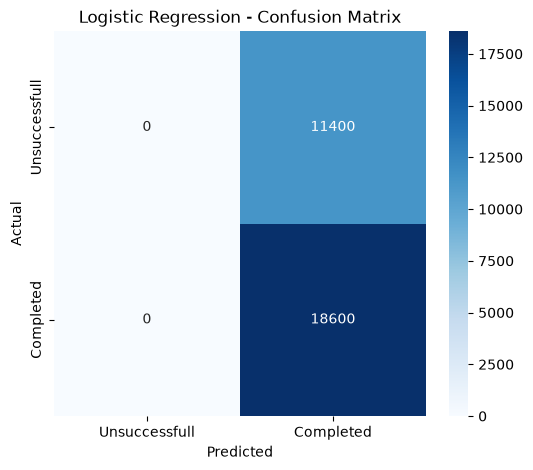

In [338]:
plt.figure(figsize=(6,5))

sns.heatmap(cm,annot = True,fmt ="d",cmap="Blues",xticklabels=["Unsuccessfull","Completed"], yticklabels=["Unsuccessfull","Completed"] )

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")

plt.tight_layout
plt.show()

In [339]:
from sklearn.metrics import classification_report

In [340]:
print(
      classification_report(y_test,y_pred,target_names=["Unsuccessfull","Completed"],zero_division =0)
)

               precision    recall  f1-score   support

Unsuccessfull       0.00      0.00      0.00     11400
    Completed       0.62      1.00      0.77     18600

     accuracy                           0.62     30000
    macro avg       0.31      0.50      0.38     30000
 weighted avg       0.38      0.62      0.47     30000



### Model Comparison & Evaluation

In [341]:
## Logistic Regression Baseline Results

In [342]:
logistic_results = pd.DataFrame({
    "Model": ["Logistic Regression"],
    "Accuracy":[accuracy],
    "Precision":[precision],
    "Recall" : [recall],
    "F1 Recall": [f1]
                                 
}) 

logistic_results.round(4)

,Model,Accuracy,Precision,Recall,F1 Recall
0,Logistic Regression,0.62,0.62,1.0,0.7654


### Dummy Baseline Model

In [343]:
from sklearn.dummy import DummyClassifier

In [344]:
dummy_model = DummyClassifier(strategy = "most_frequent")

dummy_model.fit(X_train,y_train)
dummy_pred= dummy_model.predict(X_test)

In [345]:
dummy_accuracy= accuracy_score(y_test,dummy_pred)

print("Dummy Baseline Accuracy:",round(dummy_accuracy,4))

Dummy Baseline Accuracy: 0.62


In [346]:
## ROC-AUC

In [347]:
from sklearn.metrics import roc_auc_score

In [348]:
logistic_auc = roc_auc_score(y_test,y_prob)

print("Logistic Regression ROC-AUC:",round(logistic_auc,4))

Logistic Regression ROC-AUC: 0.4969


### Random Forest Model

In [349]:
from sklearn.ensemble import RandomForestClassifier

In [350]:
random_forest_model = Pipeline(steps=[("preprocessor",preprocessor),("model", RandomForestClassifier(n_estimators=200,random_state=42,n_jobs=2))])

In [351]:
random_forest_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Vehicle Type','Pickup Location','Drop Location',...,'Booking_Day', 'Day_of_week','Is_weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

In [352]:
rf_pred = random_forest_model.predict(X_test)

rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

In [353]:
rf_accuracy= accuracy_score(y_test,rf_pred)

rf_precision = precision_score(y_test,rf_pred, zero_division=0)

rf_recall = recall_score(y_test,rf_pred, zero_division=0)

rf_f1 = f1_score(y_test,rf_pred, zero_division=0)

rf_auc = roc_auc_score(y_test,rf_prob)

print("Random Forest Results")
print("----------------------")
print("Accuracy :", round(rf_accuracy,4))
print("Precision:", round(rf_precision,4))
print("Recall   :", round(rf_recall,4))
print("F1 Score :", round(rf_f1,4))
print("ROC_AUC  :", round(rf_auc,4))


Random Forest Results
----------------------
Accuracy : 0.607
Precision: 0.6194
Recall   : 0.9496
F1 Score : 0.7498
ROC_AUC  : 0.4931


### Model Comparison

In [354]:
model_comparison = pd.DataFrame({
      "Model": [
          "Dummy Baseline",
          "Logistic Regression",
          "Random Forest"
         ],
      "Accuracy": [
          dummy_accuracy,
          accuracy,
          rf_accuracy
         ],
      "Precision": [
          np.nan,
          precision,
          rf_precision
         ],
       "Recall": [
           np.nan,
           recall,
           rf_recall
        ],
       "F1 Score": [
           np.nan,
           f1,
           rf_f1
        ],
       "ROC-AUC": [
           np.nan,
           logistic_auc,
           rf_auc
       ]
       
       
})
model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Dummy Baseline,0.620,NaN,NaN,NaN,NaN
1,Logistic Regression,0.620,0.6200,1.0000,0.7654,0.4969
2,Random Forest,0.607,0.6194,0.9496,0.7498,0.4931


In [355]:
## Random Forest Confusion Matrix

In [356]:
rf_cm = confusion_matrix(y_test,rf_pred)
print(rf_cm)

[[  549 10851]
 [  938 17662]]


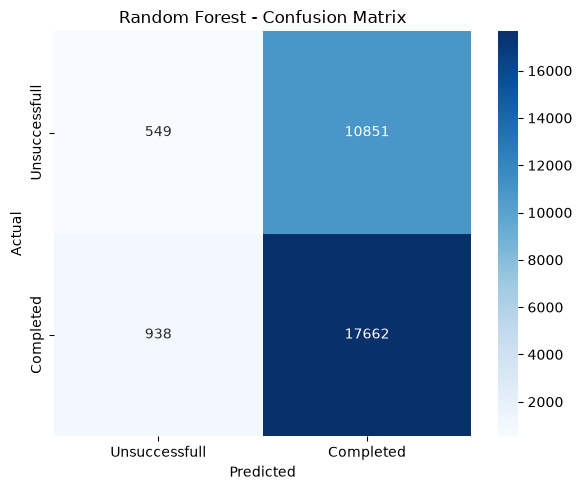

In [357]:
plt.figure(figsize=(6,5))

sns.heatmap(rf_cm, annot = True, fmt ="d", cmap="Blues",xticklabels = ["Unsuccessfull","Completed"],yticklabels = ["Unsuccessfull","Completed"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")

plt.tight_layout()
plt.show()

### ROC Curve Comparison

In [358]:
from sklearn.metrics import roc_curve

In [359]:
logistic_fpr, logistic_tpr,_ = roc_curve(y_test,y_prob)
rf_fpr, rf_tpr,_ = roc_curve(y_test,rf_prob)

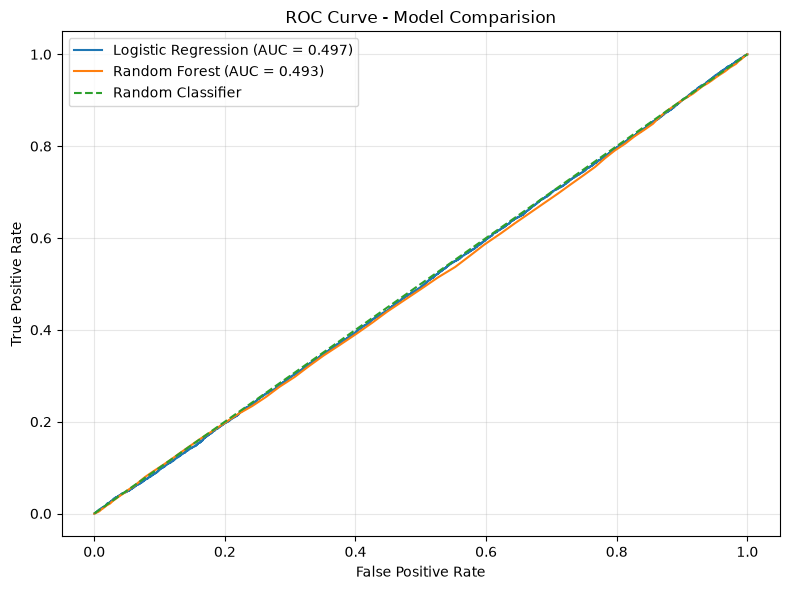

In [360]:
plt.figure(figsize=(8,6))

plt.plot(logistic_fpr, logistic_tpr, label= f"Logistic Regression (AUC = {logistic_auc:.3f})")

plt.plot(rf_fpr, rf_tpr, label = f"Random Forest (AUC = {rf_auc:.3f})")

plt.plot([0,1],[0,1],linestyle="--",label = "Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Model Comparision")

plt.legend()
plt.grid(True,alpha=0.3)
plt.tight_layout()
plt.show()

### Classification Report

In [361]:
### LOGISTIC REGRESSION

In [362]:
print("LOGISTIC REGRESSION")
print(
       classification_report(y_test,y_pred,target_names=["Unsuccessfull","Completed"],zero_division=0 ))

LOGISTIC REGRESSION
               precision    recall  f1-score   support

Unsuccessfull       0.00      0.00      0.00     11400
    Completed       0.62      1.00      0.77     18600

     accuracy                           0.62     30000
    macro avg       0.31      0.50      0.38     30000
 weighted avg       0.38      0.62      0.47     30000



In [363]:
### RANDOM FOREST

In [364]:
print("RANDOM FOREST")
print(
       classification_report(y_test,rf_pred,target_names=["Unsuccessfull","Completed"],zero_division=0 ))

RANDOM FOREST
               precision    recall  f1-score   support

Unsuccessfull       0.37      0.05      0.09     11400
    Completed       0.62      0.95      0.75     18600

     accuracy                           0.61     30000
    macro avg       0.49      0.50      0.42     30000
 weighted avg       0.52      0.61      0.50     30000



### Conclusion

Logistic Regression and Random Forest produces nearly identical classification performance, while Random Forest showed only marginal improvement in ROC-AUC. This suggests that the additional nonlinear modeling complexity of Random forest provided limited incremental value over the simpler Logistic Regression model for the selected features.

## Feature Importance & Model Interpretation

### Random Forest Feature Importance

In [365]:
# Extract the trained Random Forest Model

In [366]:
rf_model = random_forest_model.named_steps["model"]

In [367]:
# Extract the fitted preprocessor

In [368]:
rf_preprocessor= random_forest_model.named_steps["preprocessor"]

In [369]:
# Get Feature names after one-hot encoding

In [370]:
feature_names = rf_preprocessor.get_feature_names_out()

In [371]:
# Get Random Forest Feature Importance

In [372]:
rf_importance= rf_model.feature_importances_

In [373]:
# Create a DataFrame

In [374]:
rf_feature_importance = pd.DataFrame({"Features": feature_names, "Importance": rf_importance}).sort_values(by="Importance",ascending=False)

In [375]:
rf_feature_importance.head(20)

,Features,Importance
359,remainder__Booking_hour,0.084992
361,remainder__Booking_Day,0.083054
360,remainder__Booking_month,0.066703
362,remainder__Day_of_week,0.047830
0,categorical__Vehicle Type_Auto,0.013866
2,categorical__Vehicle Type_Go Mini,0.012984
3,categorical__Vehicle Type_Go Sedan,0.011527
363,remainder__Is_weekend,0.010590
1,categorical__Vehicle Type_Bike,0.010134
4,categorical__Vehicle Type_Premier Sedan,0.010080


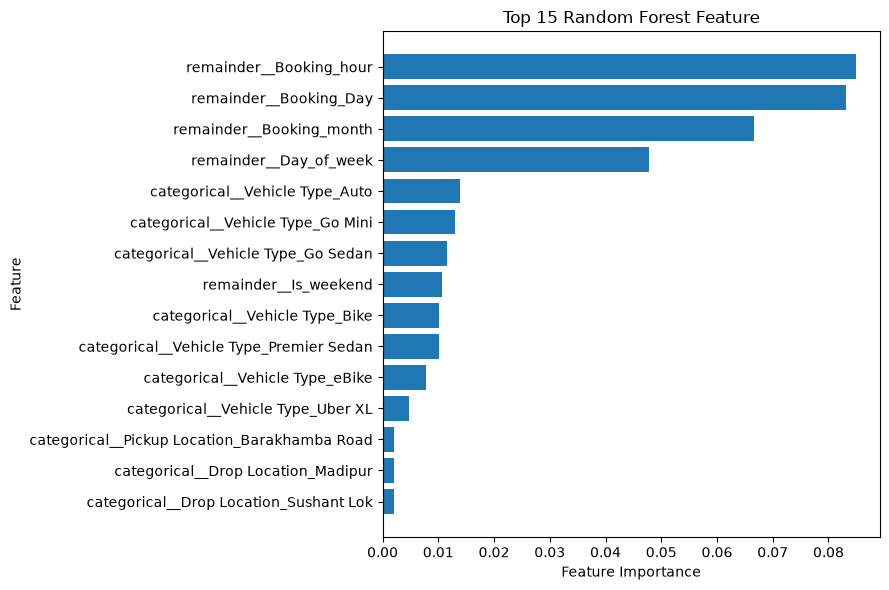

In [376]:
top_rf_features = rf_feature_importance.head(15).sort_values(by= "Importance")

plt.figure(figsize=(9,6))

plt.barh(top_rf_features["Features"],top_rf_features["Importance"])

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Random Forest Feature")

plt.tight_layout()
plt.show()

## Model Diagnostics & Feature/Leakage Analysis

### Initial Model Performance

The Initial classification model included **Payment Method** as a predictor.

The models achieved approximately:

- Logistic Regression: **93.79% accuracy, 0.9161 ROC-AUC**
- Random Forest: **93.79% accuracy, 0.9176 ROC-AUC**

At First, this appeared to indicate strong predictive performace.

### Payment Method Diagnostic

Feature-importance analysis showed that several payment method cateogries dominated the Random Forest. Further investigation revealed that missing Payment Method values were strongly associated with unsuccessfull bookings.

In [15]:
payment_status = pd.crosstab(df["Payment Method"].fillna("Missing"),df["Booking Status"],normalize="index")*100
payment_status.round(2)

Booking Status,Cancelled by Customer,Cancelled by Driver,Completed,Incomplete,No Driver Found
Payment Method,,,,,
Cash,0.00,0.00,91.12,8.88,0.00
Credit Card,0.00,0.00,91.29,8.71,0.00
Debit Card,0.00,0.00,91.35,8.65,0.00
Missing,21.88,56.25,0.00,0.00,21.88
UPI,0.00,0.00,91.12,8.88,0.00
Uber Wallet,0.00,0.00,91.28,8.72,0.00


The Missing Category contained unsuccessful booking outcomes almost exclusively, while the recorded payment methods were exclusively associated with Completed Rides.

This indicated that **Payment Method** was acting as an **Outcome proxy rather than a reliable booking-time predictor**.

Therfore,it was removed from the modeling features.

### Avg VTAT Diagnostic

**Avg VTAT** was also investigated as a potential predictor.

In [19]:
vtat_status = pd.crosstab(df["Avg VTAT"].isna(),df["Booking Status"],normalize="index")*100
vtat_status.round(2)

Booking Status,Cancelled by Customer,Cancelled by Driver,Completed,Incomplete,No Driver Found
Avg VTAT,,,,,
False,7.53,19.35,66.67,6.45,0.0
True,0.00,0.00,0.00,0.00,100.0


The Result showed:

- When VTAT was avilable, bookings could belong to multiple outcomes.
- When VTAT was missing, the bookings were **100% "No Driver Found"**.
- There were **10,500 missing VTAT values.**

Therefore, imputing the missing values and using VTAT as a booking-time predictor would allow the model to indirectly learn the outcome. **Avg VTAT** was therfore excluded from the final model.

### Refined Model Performance

AFter removing the outcome-linked features, the model was rebuilt using only cleaner booking-time information.

In [ ]:
The Results were:

 Model	           Accuracy   Precision  Recall  F1 Score  ROC-AUC
Dummy Baseline	     0.620	    NaN	      NaN	  NaN	    NaN
Logistic Regression  0.620	    0.6200	 1.0000   0.7654	0.4969
Random Forest	     0.607	    0.6194	 0.9496	  0.7498	0.4931

### Model Diagnostic Finding

The refined models performed close to the majority-class baseline, while ROC-AUC values were around 0.50.

This indicates that the remaining booking-time features provide **limited predictive signal for determining whether a ride will ultimately be completed**.

The large performance drop after removing payment method also demonstrated why model performance must be evaluated alongside feature quality and leakage checks.

## FINAL ML CONCLUSION

The initial high classification performance was influenced by features whose missingness was strongly associated with the booking outcomes. After removing these potentially outcome linked varaibles, predictive performance dropped to approximately the majority-class baseline. **This indicates that the available clean booking-time features in the Dataset are insufficient for predicting Ride completion**.